# 4-Hour Crash Course: Python + NumPy + pandas + Matplotlib + scikit-learn

## Goal
By the end of these 4 hours, you should be able to:
- write and read basic Python code confidently
- work with arrays using **NumPy**
- clean and analyze tabular data with **pandas**
- create simple plots with **Matplotlib**
- train and evaluate a first machine learning model with **scikit-learn**

This course is **hands-on**. Run every code cell and change values.


## How to use this crash course
- Use **Google Colab**, **VS Code + Jupyter**, or **Jupyter Notebook**.
- Spend **80% coding**, **20% reading**.
- Don’t aim to memorize everything. Aim to understand the workflow.
- After each section, complete the mini exercise before moving on.

Sections below each heading now explain **why** things work the way they do, not just the syntax.
Read the explanation once, then spend your time in the code cell — concepts stick when you break an
example and fix it again.


## Before you start


If you are working locally, install dependencies:

```bash
pip install numpy pandas matplotlib scikit-learn
```

In **Colab**, you can usually skip installs (but you can run the cell below if needed).


In [2]:
# Optional (Colab): install dependencies
%pip -q install numpy pandas matplotlib scikit-learn



   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ----------- ---------------------------- 2.4/8.4 MB 11.4 MB/s eta 0:00:01
   -------------------- ------------------- 4.2/8.4 MB 10.8 MB/s eta 0:00:01
   ------------------------------- -------- 6.6/8.4 MB 10.6 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 9.9 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   -- ------------------------------------- 2.1/37.4 MB 10.1 MB/s eta 0:00:04
   ---- ----------------------------------- 4.2/37.4 MB 10.3 MB/s eta 0:00:04
   ------- -------------------------------- 6.6/37.4 MB 10.1 MB/s eta 0:00:04
   --------- ------------------------------ 8.9/37.4 MB 10.3 MB/s eta 0:00:03
   ------------ --------------------------- 11.3/37.4 MB 10.4 MB/s eta 0:00:03
   -------------- ------------------------- 13.6/37.4 MB 10.4 MB/s eta 0:00:03
   ----------------- ---------------------- 16.0/37.4 MB 10.4 MB/s eta 0:00:03
   -----


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Part 1 — Python fundamentals


## 1. Variables and basic data types

In Python a variable is not a box holding a value — it is a **name bound to an object**.
`age = 30` creates an integer object and points the name `age` at it. Rebinding the name never changes
the old object; it just points the name somewhere else.

Python is **dynamically typed**: you never declare a type, the object carries its own type, and `type()`
asks the object what it is. It is also **strongly typed** — `"30" + 5` is an error, not a silent conversion.

The four basic types here: `str` (text), `int` (whole numbers, unlimited size), `float` (decimals stored
as binary approximations — which is why `0.1 + 0.2 != 0.3`), and `bool` (`True`/`False`, internally 1 and 0).


In [3]:
name = "Alice"
age = 30
height = 1.72
is_learning = True

print(name)
print(age)
print(height)
print(is_learning)

print(type(name))
print(type(age))
print(type(height))
print(type(is_learning))


Alice
30
1.72
True
<class 'str'>
<class 'int'>
<class 'float'>
<class 'bool'>


## 2. Basic operators

Two divisions exist for a reason: `/` always produces a `float` ("true division"), while `//` is
**floor division** — the result rounded down to a whole number. `%` (modulo) gives the remainder, which is
how you test divisibility (`n % 2 == 0` means "even") and how you wrap a value around a fixed range.

Precedence follows normal mathematics: `**` first, then `*  /  //  %`, then `+  -`. Use parentheses whenever
you are unsure — they cost nothing and prevent real bugs.


In [4]:
x = 10
y = 3

print(x + y)
print(x - y)
print(x * y)
print(x / y)
print(x // y) #gerundet auf nächstkleinere ganze Zahl
print(x % y) #Modulo, Rest einer Division
print(x ** y) #Potenzierung


13
7
30
3.3333333333333335
3
1
1000


## 3. Strings

Strings are **immutable**: no method modifies a string in place. `full.upper()` *returns a new string*
and leaves `full` untouched — if you don't assign the result, it is discarded. This catches almost everyone once.

An `f"..."` literal (f-string) is a **formatted string**: anything inside `{}` is evaluated as Python code and
its result inserted as text. It has replaced older `+` concatenation and `.format()` for readability.


In [5]:
first = "Python"
last = "Learner"

full = first + " " + last
print(full)
#Befehle ändern den String nicht, solange man ihm keine Variable zuweist, wird das Ergebnis verworfen
print(full.lower())
print(full.upper())
print(full.replace("Learner", "Developer"))
print(len(full))

language = "Python"
version = 3.12
print(f"I am learning {language} {version}") #ganzer Satz, Wörter in Klammern werden mit Variabeln ersetzt


Python Learner
python learner
PYTHON LEARNER
Python Developer
14
I am learning Python 3.12


## 4. Lists, tuples, dictionaries, sets

Four containers, four different jobs — choose by the guarantees you need:

- **list** `[...]` — ordered, **mutable**, duplicates allowed. The default choice for a sequence you build up or change.
- **tuple** `(...)` — ordered, **immutable**. Use for fixed records (a coordinate, a row) and anywhere a value must
  not change. Because it cannot change, it can serve as a dictionary key.
  - Liste, die nicht verändert werden kann, weil eine feste Reihenfolge besteht
- **dict** `{key: value}` — a **mapping** from keys to values. Lookup by key is near-instant regardless of size
  (it uses **hashing**), unlike scanning a list. `df["salary"]` in pandas later behaves exactly this way.
  - Schlüsselwertpaare, jeder Wert hat einen Schlüssel
- **set** `{...}` — unordered, no duplicates. Built for deduplication and membership tests (`x in s`); notice how
  the repeated values disappear on their own.
  - gibt keine Duplikate, jeder Wert kommt nur ein Mal vor

Negative indices count from the end, so `numbers[-1]` is the last item.


In [2]:
# Lists
numbers = [10, 20, 30, 40]
print(numbers[0])
print(numbers[-1]) #erste Zahl von hinten

numbers.append(50) #hinzufügen
print(numbers)

# Tuples
point = (3, 5)
print(point[0])

# Dictionaries
student = {"name": "Mia", "age": 22, "course": "Data Science"}
print(student["name"]) #in eckigen Klammern und Anführungsstriche kommt Schlüsselwort
print(student.get("age")) #oder mit get-Methode

# Sets
values = {1, 2, 2, 3, 3, 3}
print(values)


10
40
[10, 20, 30, 40, 50]
3
Mia
22
{1, 2, 3}


## 5. Conditions

An `if / elif / else` chain evaluates its conditions top to bottom and stops at the **first** one that is
true — so the order matters. If `score >= 70` came first, a score of 95 would print "Good".

Any value can act as a condition: "empty" values (`0`, `""`, `[]`, `{}`, `None`) are **falsy**, everything else is
**truthy**. And remember `=` assigns while `==` compares — confusing the two is a classic beginner bug.

Multiple conditions can be combined with `and`, `or`, and `not`. Use parentheses to clarify precedence. For example, `not a and b` is not the same as `not (a and b)`.


In [3]:
score = 78

if score >= 90:
    print("Excellent")
elif score >= 70:
    print("Good")
else:
    print("Keep practicing")

if not score < 50 and score >= 70:
    print("You passed")

if not (score < 50 or score >= 70):
    print("This will not print")


Good
You passed


## 6. Loops

A `for` loop does not count — it **iterates over a sequence**, taking one item at a time. That is why looping
over a list of strings works exactly like looping over numbers. `range(5)` yields 0,1,2,3,4 (start included, stop
excluded) and produces values **lazily**, so `range(10_000_000)` costs almost no memory.

Use `for` when you know what you are iterating over, and `while` when you repeat until a condition changes — making
sure something inside the loop actually changes that condition, or it never terminates.


In [4]:
for i in range(5):
    print(i)

fruits = ["apple", "banana", "cherry"]
for fruit in fruits:
    print(fruit)

count = 0
while count < 3:
    print(count)
    count += 1


0
1
2
3
4
apple
banana
cherry
0
1
2


## 7. Functions

A function packages logic behind a name so it can be reused and tested in isolation. Two ideas worth internalising:

- **`return` vs `print`** — `print` shows something to a human; `return` hands a value back to the calling code so it
  can be stored or used further. A function with no `return` returns `None`.
- **Default arguments** — `exponent=2` applies only when the caller omits it. Defaults are evaluated *once*, when the
  function is defined, so never use a mutable default such as `def f(items=[])`.

Variables created inside a function are **local**: they exist only while the function runs and do not leak outside it.


In [5]:
def greet(name):
    return f"Hello, {name}!"

print(greet("Sam"))

def power(base, exponent=2):
    return base ** exponent

print(power(4))
print(power(4, 3))


Hello, Sam!
16
64


## 8. List comprehensions

A comprehension is a compact `for` loop that builds a list. Read it in execution order:
`[x**2 for x in range(6)]` → "for each x in range(6), collect x²". A trailing `if` **filters** items before collecting.

It is not merely shorter than a loop with `.append()` — it also signals intent ("I am deriving a new list from an
existing one") and is usually faster. Keep comprehensions to one step of logic; anything more belongs in a normal loop.


In [6]:
squares = [x**2 for x in range(6)]
print(squares)

evens = [x for x in range(10) if x % 2 == 0]
print(evens)


[0, 1, 4, 9, 16, 25]
[0, 2, 4, 6, 8]


## 9. Error handling

When something goes wrong, Python **raises an exception** — an object describing the failure — and unwinds the
call stack until some `try/except` catches it. Uncaught, it stops the program and prints a traceback.

Catch **specific** exception types (`ZeroDivisionError`, `FileNotFoundError`, `KeyError`), never a bare `except:` —
swallowing every error hides real bugs. Python's style is "easier to ask forgiveness than permission": attempt the
operation and handle the failure, rather than checking every precondition up front.

Reading tracebacks is a core skill: the **last** line names the error type and message, and the lines above it show
the path that led there.


In [7]:
try:
    result = 10 / 0
except ZeroDivisionError:
    print("You cannot divide by zero")


You cannot divide by zero


## 10. Importing modules

`import math` loads a module and binds it as a **namespace** — its functions live under `math.`, so they cannot
collide with a `sqrt` of your own. The same mechanism explains `np.array` and `pd.DataFrame` later: `import numpy as np`
gives the namespace a short alias. If you use an alias, you cannot use the original name (`math.sqrt` is not available if you `import math as m`).

`math` ships with Python (the standard library); `numpy`, `pandas`, `matplotlib` and `scikit-learn` are third-party
packages that must be installed first.


In [8]:
import math as m
print(m.sqrt(16))

4.0


## Exercise 1 (10 minutes)
Write code that:
1. creates a list of numbers from 1 to 10
2. builds a second list containing only even numbers
3. creates a function that returns the square of a number
4. uses a loop to print the square of each even number


In [9]:
# Exercise 1 — solution
#eine Liste "numbers" wird erstellt mit Zahlen 1-10
numbers = list(range(1, 11))
#zweite Liste wird erstellt mit allen Zahlen von "numbers", die gerade sind
evens = [n for n in numbers if n % 2 == 0]
#eine Funktion, die eine Zahl potenziert
def square(n):
    return n ** 2
#alle n in "evens" sollen potenziert werden und dann nebeneinander aufgelistet werden
for n in evens:
    print(n, square(n))

2 4
4 16
6 36
8 64
10 100


# Part 2 — NumPy essentials

### Why NumPy exists

A Python list can hold anything, so every element is a separate object with its own type information, scattered across
memory. Looping over a million of them is slow.

A NumPy **`ndarray`** is the opposite: one contiguous block of memory, all elements sharing a single type (`dtype`),
with the shape stored separately. That makes two things possible:

- **Vectorization** — `arr * 2` runs the loop inside compiled C code across the whole block, typically 10–100× faster
  than a Python loop, and you write no loop at all.
- **Predictable memory** — a million floats are one 8 MB buffer, not a million objects.

Everything else in the data stack rests on this: pandas columns, Matplotlib inputs, and scikit-learn's `X` and `y` are
NumPy arrays underneath.


In [10]:
import numpy as np


## 1. Creating arrays

Every array has a single **`dtype`** shared by all its elements (`int64`, `float64`, …), inferred at creation.
Mixing types forces a common one — `np.array([1, 2.5])` becomes all floats, so `print(np.array([1, 2.5]))` prints `[1. 2.5]`.

`np.arange(start, stop, step)` behaves like `range` (stop excluded); `np.linspace(start, stop, n)` returns exactly `n`
evenly spaced values **including both ends**. Use `arange` when the step size matters and `linspace` when the number of
points matters — for example when drawing a smooth curve.


In [12]:
#erstellt einen normalen Array, in eckigen Klammern stehen die Werte, die im Array beinhaltet sein sollen
arr = np.array([1, 2, 3, 4])
print(arr)
#gibt den Datentyp von den Zahlen im Array aus
print(type(arr))
#ein Array, der Nullen erstellt, in Klammern steht die Anzahl der Nullen, die der Array enthalten soll
print(np.zeros(5))
#ein Array, der Einsen erstellt, in Klammern steht die Anzahl der Einsen, die der Array enthalten soll
print(np.ones(3))
#erstellt einen Array mit einer bestimmten Schrittweise. Man schreibt (Anfangswert, Endwert, Schrittwert)
#WICHTIG: wenn der Abstand zwischen Zahlen wichtig ist
print(np.arange(0, 10, 2))
#erstellt einen Array mit einer bestimmten Anzahl an Zahlen mit gleichmäßigen Abstand. Man schreibt (Anfangswert, Endwert, Anzahl der Elemente)
#WICHTIG: wenn die Anzahl an Elementen wichtig ist
print(np.linspace(0, 1, 5))


[1 2 3 4]
<class 'numpy.ndarray'>
[0. 0. 0. 0. 0.]
[1. 1. 1.]
[0 2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]


## 2. Shape and dimensions

`shape` is a tuple with one entry per **axis**: `(2, 3)` means 2 rows × 3 columns. `ndim` counts the axes, and
`size` is the total number of elements (the product of the shape).

The thing to memorise is the axis numbering: **axis 0 runs down the rows, axis 1 runs across the columns**. Nearly every
NumPy and pandas operation takes an `axis` argument meaning precisely this.


In [15]:
#Erstellt eine Matrix mit np.array([[], []])
#in der ersten eckigen Klammer sind alle weiteren eckigen Klammern mit den Elementen drin. Innerhalb einer eckigen Klammer ist eine Zeile.
matrix = np.array([[1, 2, 3], [4, 5, 6]])
#Wie ist die Matrix aufgebaut (Zeilen, Spalten)
print(matrix.shape)
#wie viele Dimensionen besitzt die Matrix
print(matrix.ndim)
#Wie viele Elemente besitzt die Matrix
print(matrix.size)


(2, 3)
2
6


## 3. Indexing and slicing

For 2-D arrays you give one index per axis: `matrix[row, column]`. A `:` means "everything along this axis", so
`matrix[:, 1]` is the entire second column and `matrix[1, :]` the entire second row. Slices are `start:stop` with the
**stop excluded**.


In [28]:
#Man kann auf einzelne Elemente zugreifen
#Ersteinmal wird ein eindimensionaler Array erstellt
arr = np.array([10, 20, 30, 40, 50])
#Wir printen das erste Element im Array
print(arr[0])
#Wir printen das letzte Element im Array
print(arr[-1])
#Element von Index 1 bis Index 4, beim Slicing wird der Endindex nicht mitgezählt
print(arr[1:4])
#Wir erstellen eine Matrix, dafür brauchen wir zwei Indizes matrix(zeile, spalte)
matrix = np.array([[1, 2, 3], [4, 5, 6]])
#Wir printen das erste Element in der zweiten Spalte
print(matrix[0, 1])
#Wir printen alle Elemente aus der zweiten Spalte
print(matrix[:, 1])
#Wir printen die 2. Elemente aus allen Spalten
print(matrix[1, :])

#Wir haben noch matrix.sum(axis=0) hier werden alle Elemente einer Spalte summiert
#Wir haben noch matrix.sum(axis=1) hier werden alle Elemente einer Zeile summiert


10
50
[20 30 40]
2
[2 5]
[4 5 6]


One important difference from lists: a NumPy slice is a **view**, not a copy — it refers to the same memory. Writing into
a slice therefore modifies the original array. Use `.copy()` when you need an independent one.

In [24]:
#das, was man an Infos rausfiltert ist eine Ansicht und keine Kopie
#Wir erstellen einen Array mit den Zahlen 0-4
a = np.arange(5)
#Wir wählen die ersten drei Elemente von a aus
b = a[:3]
#Wir nehmen das erste Element von b und ersetzen es mit 99
b[0] = 99
print(b)
#Wir speichern die drei Elemente wie von b mit .copy() in einer unabhängigen Variable c
c = a[:3].copy()
#Wir setzen das erste Element wieder auf 0, a beinhaltet aber immernoch 99, wie wir es in b verändert haben
c[0] = 0
print(c)
print(a)

[99  1  2]
[0 1 2]
[99  1  2  3  4]


## 4. Vectorized operations

Arithmetic on arrays is **element-wise**: `arr + 10` adds 10 to every element and returns a new array, no loop
required. When shapes differ, NumPy **broadcasts** — it stretches the smaller operand across the larger wherever the
shapes are compatible, which is how a single number can apply to every element.

Comparisons behave the same way: `arr > 2` returns an array of booleans, one per element, not a single True/False.
That boolean array is the key to the filtering below.

Broadcasting is the general rule behind this; **section 9** works through which mismatched shapes are allowed to combine and which are not.


In [26]:
#Wenn man einen Array mit einer Matheaufgabe verknüpft, wird die Rechnung mit jedem einzelnen Element im Array durchgeführt
#Wir erstellen einen Array
arr = np.array([1, 2, 3, 4])
print(arr + 10)
print(arr * 2)
print(arr ** 2)
print(arr > 2)


[11 12 13 14]
[2 4 6 8]
[ 1  4  9 16]
[False False  True  True]


## 5. Aggregations

Aggregations **reduce** an array to fewer numbers. On a 2-D array you choose the direction with `axis`:
`m.sum(axis=0)` collapses the rows (one total per column), `axis=1` collapses the columns (one total per row).

One detail that trips people up: NumPy's `.std()` computes the **population** standard deviation (dividing by n), while
pandas' `.std()` defaults to the **sample** version (dividing by n−1). The same data can therefore give slightly different
numbers; pass `ddof=1` to NumPy to match pandas.


In [27]:
#Wir erstellen eine eindimensionale Matrix
arr = np.array([2, 4, 6, 8])
#arithmetischer Mittelwert
print(arr.mean())
#Summe aller Elemente
print(arr.sum())
#kleinster Wert
print(arr.min())
#größter Wert
print(arr.max())
#Standartabweichung
print(arr.std())

#Wir erstellen eine mehrdimensionale Matrix
matrix = np.array([[1, 2, 3], [4, 5, 6]])
# axis=1 bedeutet der Mittelwert jeder Zeile
print(matrix.mean(axis=1))


5.0
20
2
8
2.23606797749979
[2. 5.]


## 6. Reshaping

Reshaping changes how the same buffer of values is *interpreted*, not the values themselves — so the new shape must
have the same total size (12 = 3 × 4). NumPy fills **row by row** (C order) by default.

`-1` means "work it out for me": `arr.reshape(3, -1)` gives 3 rows and as many columns as that requires. You will need this
when a model expects a 2-D `X` and you hold a 1-D array: `x.reshape(-1, 1)`.


In [17]:
#Wir erstellen eine eindimensionale Matrix mit 12 Elementen
arr = np.arange(12)
#mit .reshape(zeilen, spalten) kann man daraus eine Matrix machen
reshaped = arr.reshape(3, 4)
print(reshaped)
#Wenn das ursprüngliche Array 12 Elemente besitztm muss auch das umgeformte Array 12 Elemente besitzen. Wenn die Anzahl nicht übereinstimmt entsteht ein ERROR
#mit reshape(3,-1) gibt man vor, dass die Matrix drei Zeilen haben soll und NumPy die Anzahl der Spalten vorgeben soll

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]


## 7. Boolean filtering

This one line is really two steps. `arr > 10` builds a **boolean mask** `[False, True, False, True, False]`; then
`arr[mask]` keeps only the positions where the mask is `True`.

Learn this pattern properly — pandas filtering (`df[df["age"] > 30]`) is the identical idea applied to rows of a table.
Masks combine with `&` (and), `|` (or) and `~` (not), always with parentheses around each condition. `or` and `and` are **not** overloaded for arrays, so they do not work.


In [33]:
#Wir erstellen einen Array
arr = np.array([5, 12, 7, 20, 3])
#Wir printen nur die Zahlen aus dem Array, die größer als 10 sind
#Jedes Element wird überprüft, ob es größer als 10 ist
print(arr[arr > 10])
#Mit normalen runden Klammern erhält man die boolschen Werte
print(arr>10)

# Example for & and |
#Man kann auch mehrere Bedingungen kombinieren ~ heißt nicht
arr = np.array([[1, 2, 3], [4, 5, 6]])
print((arr < 2) | (arr > 5))


[12 20]
[False  True False  True False]
[[ True False False]
 [False False  True]]


## 8. Random numbers

Computers do not produce true randomness; they run a deterministic **pseudo-random number generator** whose starting
point is the *seed*. Fixing the seed (`np.random.seed(42)`) makes the "random" sequence identical on every run and on every
machine.

That is why seeds appear throughout data science: **reproducibility**. Without one your results shift with each run and you
cannot tell whether a changed score came from your code or from luck. `rand` draws uniformly from [0, 1); `randint` draws
whole numbers with the upper bound excluded.


In [34]:
#Wir legen den Startwert des Zufallszahlengenerators fest
np.random.seed(0) #derselbe SEED sorgt immer für die selben Zufallszahlen
#Wir printen 5 zufällige Fließkommazahlen zwischen 0 und 1
print(np.random.rand(5))
#Hier können wir mehr festlegen (kleinste mögliche Zahl - enthalten, Obergrenze - nicht enthalten, Anzahl der Zufallszahlen)
print(np.random.randint(1, 10, size=5))


[0.5488135  0.71518937 0.60276338 0.54488318 0.4236548 ]
[6 3 5 8 7]


## 9. Broadcasting

Broadcasting is the rule NumPy applies when an operation involves arrays of **different shapes**. Instead of refusing,
or making you build matching copies by hand, it *virtually* stretches the smaller array along the axes where it is
missing or has length 1.

The rule is applied axis by axis, **starting from the right**:

1. If one array has fewer dimensions, its shape is padded with 1s on the **left**.
2. Two axes are compatible if they are **equal**, or if **one of them is 1**.
3. An axis of length 1 is stretched to match the other.
4. If any pair is incompatible, NumPy raises a `ValueError` instead of guessing.

```
(3, 4)  +  (4,)      ->  (4,) padded to (1, 4), stretched to (3, 4)     OK
(3, 4)  +  (3,)      ->  (3,) padded to (1, 3), and 3 != 4              ValueError
(3, 4)  +  (3, 1)    ->  the 1 is stretched to 4                        OK
(3, 1)  +  (1, 4)    ->  both are stretched                             -> (3, 4)
(3, 4)  +  scalar    ->  a scalar has shape (), so it fits anything     OK
```

Nothing is copied. Along a stretched axis NumPy simply walks the memory with a **stride of 0**, reading the same value
again and again — so broadcasting costs no extra memory and no Python loop. That is what makes `arr + 10` and
"subtract the column means" cheap even on large arrays.

The case worth memorising is the last mismatch above: a 1-D array is always treated as a **row**. When you mean a
**column**, say so explicitly with `.reshape(-1, 1)`.


In [40]:
#REGELN
#Hat ein Array weniger Dimensionen, werden links gedanklich Dimensionen der Größe 1 ergänzt.
#Zwei Dimensionen sind kompatibel, wenn sie gleich groß sind oder mindestens eine davon 1 ist.
#Eine Dimension der Größe 1 kann auf die benötigte Größe erweitert werden.
#Sind die Dimensionen nicht kompatibel, entsteht ein ValueError.
#mit Broadcasting kann man Arrays unterschiedlicher Formen miteinander verrechnen, ohne Größe anpassen zu müssen
#Wir erstellen eine Matrix mit 12 Elementen und ordnen sie dann zu einer mehrdimensionalen Matrix mit 3 Zeilen und 4 Spalten
matrix = np.arange(12).reshape(3, 4)
print(matrix)
print()

#Wir addieren zu jedem Element in der Matrix 100 dazu
# 1) scalar: stretched across every element
print(matrix + 100, "\n")

#Wir erstellen einen Zeilenvektor und addieren ihn zur Matrix dazu (als würde der eindimensionale Vektor in jeder Zeile stehen
# 2) row vector (4,) -> one value per column
col_offset = np.array([0, 10, 20, 30])
print(matrix + col_offset, "\n")          # (3, 4) + (4,) -> (3, 4)

#Wollen wir einen Spaltenvektor addieren, können wir durch reshape aus dem Zeilenvektor ein Spaltenvektor machen
# 3) column vector (3, 1) -> one value per row
row_offset = np.array([0, 100, 200]).reshape(-1, 1)
print(matrix + row_offset, "\n")          # (3, 4) + (3, 1) -> (3, 4)

# 4) (3, 1) + (1, 4): both are stretched into a full grid
print(np.array([[1], [2], [3]]) + np.array([[10, 20, 30, 40]]), "\n")

# 5) practical use: centre each column on its own mean
print(matrix.mean(axis=0))                 # shape (4,) - one mean per column
print(matrix - matrix.mean(axis=0), "\n")  # (3, 4) - (4,) -> (3, 4)

# 6) shapes that cannot broadcast
try:
    matrix + np.array([1, 2, 3])           # (3, 4) + (3,) -> 3 does not match 4
except ValueError as e:
    print("ValueError:", e)

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

[[100 101 102 103]
 [104 105 106 107]
 [108 109 110 111]] 

[[ 0 11 22 33]
 [ 4 15 26 37]
 [ 8 19 30 41]] 

[[  0   1   2   3]
 [104 105 106 107]
 [208 209 210 211]] 

[[11 21 31 41]
 [12 22 32 42]
 [13 23 33 43]] 

[4. 5. 6. 7.]
[[-4. -4. -4. -4.]
 [ 0.  0.  0.  0.]
 [ 4.  4.  4.  4.]] 

ValueError: operands could not be broadcast together with shapes (3,4) (3,) 


## Exercise 2 (10 minutes)
1. create an array from 1 to 20
2. select only values greater than 10
3. reshape the array into 4 rows and 5 columns
4. calculate the mean of all numbers


In [35]:
# Exercise 2 — solution
arr = np.arange(1, 21)
print(arr[arr > 10])
print(arr.reshape(4, 5))
print(arr.mean())


[11 12 13 14 15 16 17 18 19 20]
[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]]
10.5


# Part 3 — pandas essentials

### What a DataFrame actually is

A **`DataFrame`** is a table whose columns are **`Series`** — one-dimensional, NumPy-backed arrays that all share the same
**index** (the row labels printed on the left). Think "dictionary of columns", not "list of rows".

Two consequences explain most of pandas' behaviour:

- Each column carries its **own dtype**. A single column is fast and homogeneous like a NumPy array, while the table as a
  whole can still mix numbers, text and dates across columns.
- Operations **align on the index**, not on position. When two Series are combined, pandas matches labels first — which is
  why the index deserves more attention than beginners usually give it.


In [41]:
import pandas as pd


## 1. Create a DataFrame

Building from a dictionary is the most common route: **keys become column names** and each list becomes a column.
All the lists must have the same length. Since no index was supplied, pandas creates a default `RangeIndex` from 0 to n−1.


In [43]:
#wir erstellen ein Dictionary
data = {
    "name": ["Anna", "Ben", "Cara", "Dan"],
    "age": [23, 35, 29, 41],
    "salary": [40000, 52000, 48000, 61000],
    "department": ["HR", "IT", "IT", "Finance"],
}

#Mit pd.DataFrame(data) erstellen wir ein DataFrame
df = pd.DataFrame(data)
print(df)


   name  age  salary department
0  Anna   23   40000         HR
1   Ben   35   52000         IT
2  Cara   29   48000         IT
3   Dan   41   61000    Finance


## 2. Inspecting data

Always look at a dataset before computing anything from it. Each command answers a different question:

- `head()` — do the values look plausible?
- `shape` — how many rows and columns?
- `dtypes` / `info()` — did anything numeric arrive as **`object`** (pandas' catch-all for text)? A stray "N/A" or a comma
  used as decimal separator is the usual cause, and it silently breaks arithmetic later on.
- `describe()` — count, mean, spread and quartiles for **numeric columns only**; a good place to spot impossible minimums
  or extreme outliers.

`info()` also reports non-null counts per column, which is your first read on missing data.


In [44]:
#Die ersten zwei Zeilen werden angezeigt
print(df.head(2))
#es wird angezeigt wie viele (Zeilen, Spalten) die Tabelle besitzt
print(df.shape)
#die Spaltennamen werden angezeigt
print(df.columns)
#die Datentypen werden angezeigt
print(df.dtypes)
#gibt eine Übersicht aus
print(df.info())
#gibt statistische Kennzahlen aus
print(df.describe())


   name  age  salary department
0  Anna   23   40000         HR
1   Ben   35   52000         IT
(4, 4)
Index(['name', 'age', 'salary', 'department'], dtype='str')
name            str
age           int64
salary        int64
department      str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   name        4 non-null      str  
 1   age         4 non-null      int64
 2   salary      4 non-null      int64
 3   department  4 non-null      str  
dtypes: int64(2), str(2)
memory usage: 260.0 bytes
None
             age        salary
count   4.000000      4.000000
mean   32.000000  50250.000000
std     7.745967   8732.124598
min    23.000000  40000.000000
25%    27.500000  46000.000000
50%    32.000000  50000.000000
75%    36.500000  54250.000000
max    41.000000  61000.000000


## 3. Selecting columns and rows

`df["name"]` returns a **Series** (a single column); `df[["name", "salary"]]` — note the *list* inside the brackets —
returns a **DataFrame**. Same data, different shape, and models generally require the 2-D form.

For rows, the two accessors differ in what they accept:

- **`.loc[]` works on labels**, and its slices are **inclusive** at both ends — `df.loc[0:2]` returns three rows.
- **`.iloc[]` works on integer positions**, and is **exclusive** at the end like ordinary Python slicing — `df.iloc[0:2]`
  returns two rows.

Here the labels happen to *be* 0,1,2,3, which hides the distinction. After sorting or filtering, the index no longer matches
position and the two diverge sharply.


In [45]:
#Spalten anhand ihres Namens auswählen
print(df["name"])
print(df[["name", "salary"]])

#Daten anhand ihrer Indexbezeichnung auswählen
print(df.loc[0])
print(df.loc[0:2, ["name", "salary"]])

#Daten anhand ihrer Position auswählen
print(df.iloc[0:2, 1:3])


0    Anna
1     Ben
2    Cara
3     Dan
Name: name, dtype: str
   name  salary
0  Anna   40000
1   Ben   52000
2  Cara   48000
3   Dan   61000
name           Anna
age              23
salary        40000
department       HR
Name: 0, dtype: object
   name  salary
0  Anna   40000
1   Ben   52000
2  Cara   48000
   age  salary
0   23   40000
1   35   52000


## 4. Filtering rows

The same idea as NumPy masking: `df["age"] > 30` produces a boolean Series, and `df[...]` keeps the rows where it is `True`.

To combine conditions you must use `&`, `|` and `~` — **not** `and`, `or`, `not`, which try to collapse an entire Series into a
single truth value and raise an error. Each condition also needs its own parentheses, because in Python `&` binds more tightly
than `>`.


In [46]:
#Wir printen im DataFrame nur die Werte, wo die Bedingung erfüllt ist
print(df[df["age"] > 30])
print(df[df["department"] == "IT"])
print(df[(df["age"] > 25) & (df["salary"] > 45000)])


  name  age  salary department
1  Ben   35   52000         IT
3  Dan   41   61000    Finance
   name  age  salary department
1   Ben   35   52000         IT
2  Cara   29   48000         IT
   name  age  salary department
1   Ben   35   52000         IT
2  Cara   29   48000         IT
3   Dan   41   61000    Finance


## 5. Creating and modifying columns

`df["salary"] * 0.10` multiplies the whole column at once (vectorized, no loop), and assigning to a new key adds the
column in place. Prefer this to iterating over rows: it is shorter, much faster, and far less error-prone.

When you assign a Series, pandas **aligns on the index** — rows are matched by label rather than by order, and labels with no
match become `NaN`.


In [47]:
#Wir fügen eine neue Zeile dazu, inhaltlich soll sie salary *0.10 beinhalten
df["bonus"] = df["salary"] * 0.10
df["age_in_5_years"] = df["age"] + 5
print(df)


   name  age  salary department   bonus  age_in_5_years
0  Anna   23   40000         HR  4000.0              28
1   Ben   35   52000         IT  5200.0              40
2  Cara   29   48000         IT  4800.0              34
3   Dan   41   61000    Finance  6100.0              46


## 6. Sorting

`sort_values` returns a **new** DataFrame; the original is unchanged unless you reassign it. The index travels with the
rows, so after sorting the labels are no longer in ascending order — exactly the situation in which `.loc` and `.iloc` stop
agreeing. Use `reset_index(drop=True)` when you want a clean renumbering.

Differences to lists: `.sort()` changes the original and returns None:
`my_list.sort()`

In pandas: `.sort_values()` returns a new DataFrame by default:
`df = df.sort_values("column")`

You can also change the DataFrame directly with:
`df.sort_values("column", inplace=True)`


In [46]:
#Wir erstellen ein neues DataFrame, in dem die Zeilen nach salary sortiert sind
print(df.sort_values("salary", ascending=False))
#inplace=TRUE würde das alte DataFrame ändern


   name  age  salary department
3   Dan   41   61000    Finance
1   Ben   35   52000         IT
2  Cara   29   48000         IT
0  Anna   23   40000         HR


## 7. Grouping and aggregation

`groupby` implements **split–apply–combine**: split the rows into groups by a key column, apply an aggregation within
each group, then combine the results into a new table indexed by the group key.

The aggregation collapses many rows into one value per group (`mean`, `sum`, `count`, `max`, …), and `.agg({...})` lets you
apply a different function per column. This is the single most useful pandas verb for answering any "… by category" question.


In [ ]:
#man kann verschiedene Daten anhand einer Spalte in Gruppen aufteilen
#df.groupby("department") gruppiert alle Personen nach ihrer Abteilung
#["salary"] wählt innerhalb jeder Gruppe die Gehaltsspalte aus
#.mean() berechnet das durchschnittliche Gehalt pro Gruppe
print(df.groupby("department")["salary"].mean())

#mit .agg() kann man unterschiedliche Berechnungen auf verschiedene Spalten anwenden
print(df.groupby("department").agg({"salary": "mean", "age": "max"}))


## 8. Missing values

Missing values are represented by `NaN` ("not a number"), which is a special **float** — that is why an integer column
containing a gap turns into a float column. `NaN` propagates through arithmetic and never equals itself, so you test with
`.isna()` rather than `== NaN`. Most aggregations skip it silently, so a mean may quietly be computed over fewer rows than
you assume.

`isna().sum()` per column is the standard first diagnostic. Then choose deliberately:

- **`dropna()`** — reasonable when few rows are affected; wasteful and possibly biased if the missingness is systematic
  (e.g. high earners declining to state a salary).
- **`fillna(0)`** — only when zero is genuinely the correct value; otherwise it distorts means and models.
- **`fillna(mean)`** (imputation) — keeps the row usable, at the cost of slightly shrinking the variance.

One rule for later: when the data feeds a model, compute the fill value from the **training set only**, or information from
the test set leaks into training.


In [48]:
#NaN bedeutet not a number
data2 = {
    "name": ["Anna", "Ben", None, "Dan"],
    "score": [90, None, 85, 88]
}

df2 = pd.DataFrame(data2)
print(df2) #alle fehlenden Werte werden mit NaN aufgefüllt
print(df2.isna()) #ob Werte fehlen oder nicht
print(df2.isna().sum()) #zählt alle fehlenden Werte

print(df2.dropna()) #fehlende Werte werden entfernt, also die gesamte Zeile
print(df2.fillna(0)) #fehlende Werte werden mit 0 aufgefüllt
print(df2["score"].fillna(df2["score"].mean())) #fehlende Werte werden mit dem Mittelwert aufgefüllt


   name  score
0  Anna   90.0
1   Ben    NaN
2   NaN   85.0
3   Dan   88.0
    name  score
0  False  False
1  False   True
2   True  False
3  False  False
name     1
score    1
dtype: int64
   name  score
0  Anna   90.0
3   Dan   88.0
   name  score
0  Anna   90.0
1   Ben    0.0
2     0   85.0
3   Dan   88.0
0    90.000000
1    87.666667
2    85.000000
3    88.000000
Name: score, dtype: float64


## 9. Reading and writing files

`read_csv` does more than read text: it infers column types, handles the header row, and converts recognised markers
(empty fields, `NA`) into `NaN`. When numbers arrive as `object`, the fix is almost always an argument here — `sep`, `decimal`,
`na_values`, `encoding`, `parse_dates`.

Pass `index=False` when writing, or your row labels reappear as an unnamed extra column the next time the file is read.


```python
# df = pd.read_csv("data.csv")
# df = pd.read_excel("data.xlsx")
# df.to_csv("output.csv", index=False)
```


## 10. Value counts and unique values

For categorical columns these are the counterpart to `describe()`. `unique()` shows which categories exist — and exposes
typos or inconsistent casing such as "IT" vs "it" — while `value_counts()` shows how frequent each one is, which also reveals
whether the classes are **imbalanced**, something that changes how a classifier should be judged later. Add `dropna=False`
to count missing values as well.


In [ ]:
#zählt wie oft jeder unterschiedliche Wert in der Spalte department vorkommt
print(df["department"].value_counts())
#zeigt eindeutige Werte an
print(df["department"].unique())


## Exercise 3 (15 minutes)
Using this dataset:

```python
sales = pd.DataFrame({
    "product": ["A", "B", "A", "C", "B", "A"],
    "region": ["North", "South", "North", "West", "South", "West"],
    "units": [10, 15, 8, 12, 20, 5],
    "price": [100, 120, 100, 150, 120, 100]
})
```

Tasks:
1. add a new column called `revenue = units * price`
2. show only rows where revenue is greater than 1200
3. calculate total revenue by product
4. find the average units sold by region


In [ ]:
# Exercise 3 — solution
sales = pd.DataFrame({
    "product": ["A", "B", "A", "C", "B", "A"],
    "region": ["North", "South", "North", "West", "South", "West"],
    "units": [10, 15, 8, 12, 20, 5],
    "price": [100, 120, 100, 150, 120, 100]
})

sales["revenue"] = sales["units"] * sales["price"]
print(sales)
print(sales[sales["revenue"] > 1200])
print(sales.groupby("product")["revenue"].sum())
print(sales.groupby("region")["units"].mean())


# Part 4 — Matplotlib essentials

### How Matplotlib is organised

Every plot lives in a **Figure** (the canvas), which contains one or more **Axes** (a single plot with its x- and y-axis).
`plt.plot(...)` uses the *pyplot* interface, which keeps a "current figure" in the background and applies each command to it —
short and convenient for a quick look.

For anything more substantial, the explicit object-oriented form is worth knowing: `fig, ax = plt.subplots()` followed by
`ax.plot(...)` makes multi-panel figures and reusable plotting functions straightforward. `plt.show()` renders the current
figure and clears it — without it, later commands would keep adding to the same plot.


In [50]:
import matplotlib.pyplot as plt


## 1. Basic line plot

A line plot implies the x-axis has a **meaningful order** — time, or some continuous quantity — because the connecting
line asserts that the points lie on a path. For unordered categories a bar chart is the honest choice. Axis labels and a title
are not decoration: a plot lacking them cannot be interpreted by anyone else.


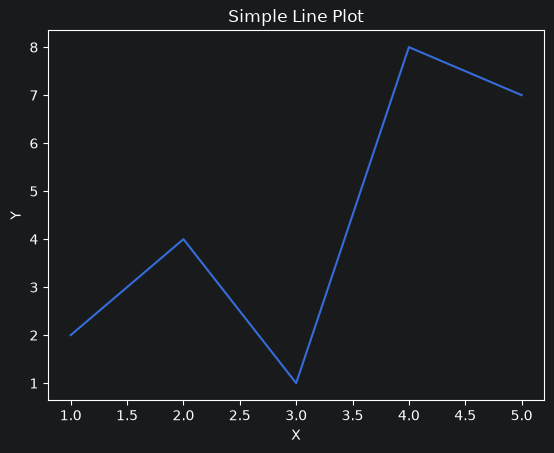

In [51]:
#wir erstellen ein Liniendiagramm
#wir geben x-Koordinaten und Y-Koordinaten
x = [1, 2, 3, 4, 5]
y = [2, 4, 1, 8, 7]

#Wir erstellen das Liniendiagramm mit plt.plot(x, y)
plt.plot(x, y)
plt.title("Simple Line Plot")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()


## 2. Bar chart

Bars encode value by **length** measured from a shared baseline, which is why a bar chart's y-axis must start at zero —
otherwise the visual comparison exaggerates the differences. Use bars for counts and totals across discrete categories.


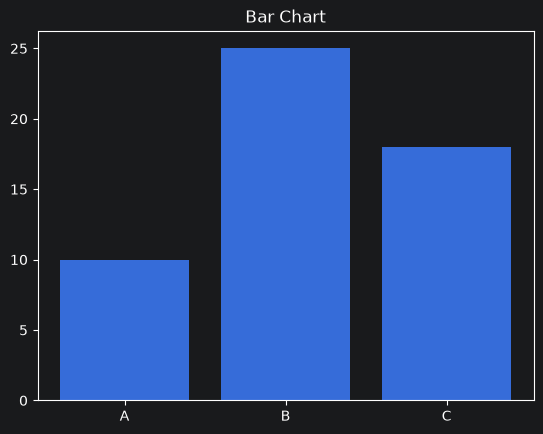

In [53]:
#Wir erstellen ein Säulendiagramm
#Wir erstellen Werte für X und Werte für Y
categories = ["A", "B", "C"]
values = [10, 25, 18]

#Wir erstellen das Säulendiagramm mit plt.bar(x, y)
plt.bar(categories, values)
plt.title("Bar Chart")
plt.show()


## 3. Histogram

A histogram is not a bar chart. It takes **one** continuous variable, cuts its range into **bins**, and shows how many
values fall into each — revealing the shape of the **distribution**: where the mass sits, whether it is symmetric or skewed,
whether there is one peak or several, and where outliers lie.

`bins` is a genuine analytical choice: too few hides structure, too many turns the shape into noise. Try `bins=5` and
`bins=200` on this same data to see the effect. (`np.random.randn` draws from the standard normal distribution, so the
expected shape is the bell curve.)


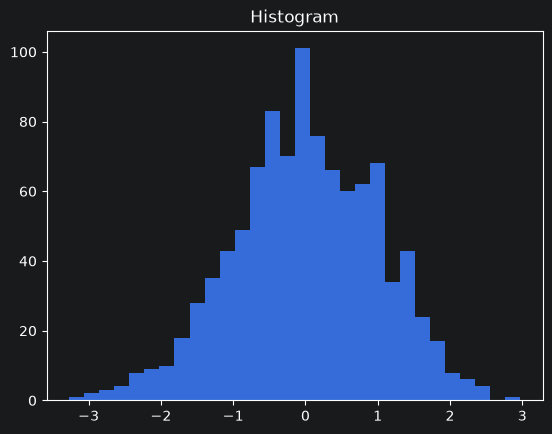

In [54]:
#Wir erstellen ein Histogramm (zeigt wie häufig bestimmte Werte innerhalb eines Zahlenbereichs vorkommen
data = np.random.randn(1000) #erzeugt 1000 zufällige Zahlen aus einer Standardnormalverteilung
plt.hist(data, bins=30) #erstellt ein Histogramm mit 30 Klassen
plt.title("Histogram")
plt.show()


## 4. Scatter plot

A scatter plot shows the **relationship between two continuous variables**, one point per observation: its direction
(does y rise with x?), strength (how tight is the cloud?), shape (straight or curved?), and any outliers.

It is the plot to draw before fitting a regression, because it tells you whether a straight line is even a defensible model.
And the standard caution applies: a visible association is **correlation, not causation**.


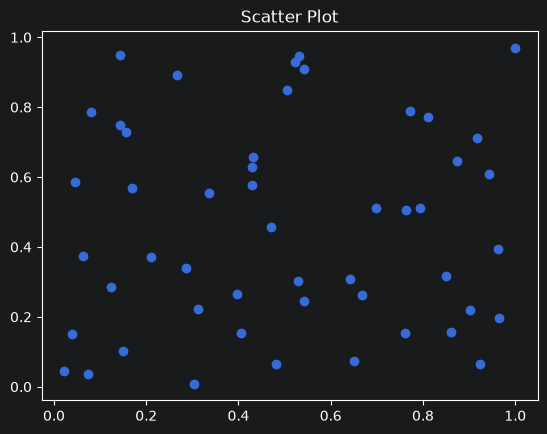

In [56]:
#Wir erstellen ein Streudiagramm
x = np.random.rand(50) #erzeugt 50 Zufallszahlen
y = np.random.rand(50)

#wir zeichnen das Streudiagramm und lassen uns die Werte für x bzw y übergeben
plt.scatter(x, y)
plt.title("Scatter Plot")
plt.show()


## 5. Plotting directly from pandas

pandas has plotting built in — `series.plot(kind="bar")` calls Matplotlib for you, using the index as the x-axis and the
values as the y-axis. That is why `groupby(...).mean().plot(kind="bar")` in the next exercise works with no extra wiring: the
group keys are already the index. Any `plt.*` command afterwards still adjusts the resulting figure.


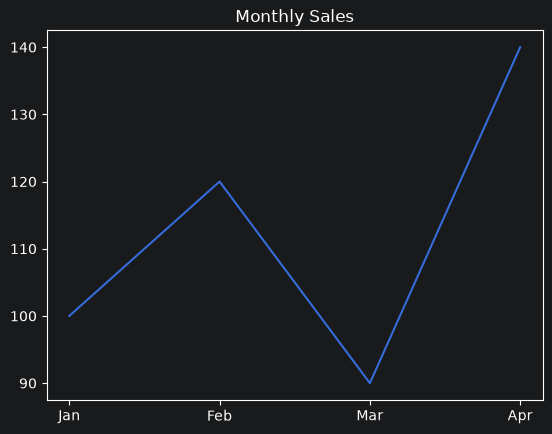

In [57]:
#man kann Diagramme auch direkt mit einem pandas-DataFrame erstellen
#wir erstellen eine Tabelle mit zwei Spalten
df_plot = pd.DataFrame({
    "month": ["Jan", "Feb", "Mar", "Apr"],
    "sales": [100, 120, 90, 140]
})
#wir erstellen ein Diagramm mit den Werten vom DataFrame
plt.plot(df_plot["month"], df_plot["sales"])
plt.title("Monthly Sales")
plt.show()


## Exercise 4 (5 minutes)
Using the `sales` DataFrame from Exercise 3:
1. create a bar chart of total revenue by product
2. create a bar chart of average units by region


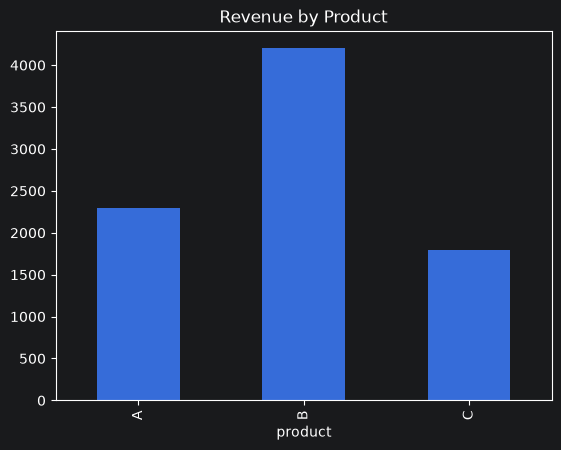

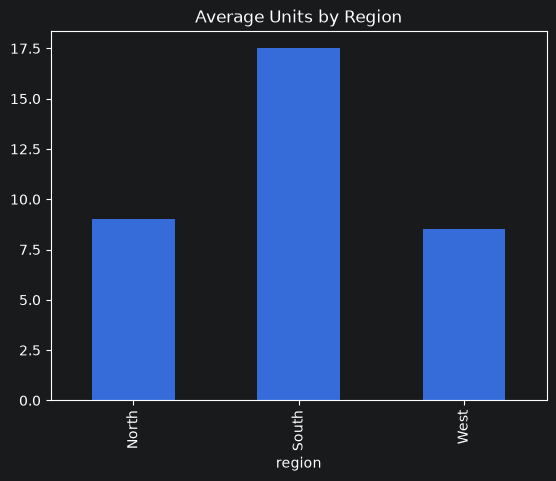

In [59]:
# Exercise 4 — solution
# Assumes `sales` already exists and includes a 'revenue' column.
sales = pd.DataFrame({
    "product": ["A", "B", "A", "C", "B", "A"],
    "region": ["North", "South", "North", "West", "South", "West"],
    "units": [10, 15, 8, 12, 20, 5],
    "price": [100, 120, 100, 150, 120, 100]
})

sales["revenue"] = sales["units"] * sales["price"]

sales.groupby("product")["revenue"].sum().plot(kind="bar", title="Revenue by Product")
plt.show()

sales.groupby("region")["units"].mean().plot(kind="bar", title="Average Units by Region")
plt.show()


# Part 5 — scikit-learn essentials

### The idea behind supervised learning

You have a matrix of **features** `X` (one row per observation, one column per input variable) and a **target** `y` (the known
answer for each row). A model learns a mapping from `X` to `y` on data where the answer is known, so that it can predict `y` for
rows where it is not.

Two kinds of target:

- **Regression** — `y` is a continuous number (price, exam score).
- **Classification** — `y` is a category (flower species, spam / not spam).

scikit-learn puts every model behind the same small **estimator API**, so swapping algorithms is a one-line change:

- `model.fit(X_train, y_train)` — learn the parameters from training data
- `model.predict(X_new)` — apply what was learned
- `model.score(X_test, y_test)` — a default quality measure
- transformers add `.transform()` and `.fit_transform()`

And one rule underlies all of it: **`fit` may only ever see training data.**

Note that in scikit-learn models assume data in the same format as they were trained on: the same columns, the same scaling, the same order, the same encoding. If you change the data, you must re-train the model.


In [60]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


## 1. First regression model

**Linear regression** fits `price ≈ b₀ + b₁·size + b₂·rooms`, choosing the coefficients that minimise the sum of squared
errors. The fitted values (`model.coef_`, `model.intercept_`) are directly readable: each coefficient is the expected change in
price per additional unit of that feature, holding the others fixed.

**Why split into train and test?** A model evaluated on the data it learned from tells you how well it memorised, not how well
it **generalises**. Holding back a test set that `fit` never saw is the only honest estimate available. `random_state=42` fixes
the random shuffle so the split is reproducible.

**Reading the metrics:**

- **MAE** (mean absolute error) — the average size of the error, expressed in the target's own units. An MAE of 5 means
  "off by about 5 thousand on average".
- **R²** — the share of the target's variance the model explains: 1.0 is perfect, 0 is no better than always predicting the
  mean, and a negative value is worse than that.

With 8 rows and only 2 test points, treat these numbers as a demonstration of the mechanics rather than as evidence about the model.


In [61]:
#ein Modell erstellen, das anhand von vorhandenen Daten Vorhersagen trifft
#lineare Regression versucht einen linearen Zusammenhang zwischen Eingabewerten (X)  und einer Zielvariable (Y) zu finden

#Wir erstellen ein DataFrame mit den schon vorhandenen Daten
housing = pd.DataFrame({
    "size": [50, 60, 70, 80, 90, 100, 110, 120],
    "rooms": [2, 2, 3, 3, 3, 4, 4, 5],
    "price": [150, 180, 210, 240, 270, 300, 330, 360]
})
# Wir erstellen die Variablen X und Y
# X enthält die Eingabemerkmale
# Y enthält die bekannten Werte
X = housing[["size", "rooms"]]
y = housing["price"]

#Wir teilen Trainings- und Testdaten auf
#0.25 der Daten werden zum Testen aufgeteilt
#random_state=24 sorgt für eine reproduzierbare zufällige Aufteilung
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

#Wir erstellen ein Modell
model = LinearRegression()
#wir trainieren das Modell
model.fit(X_train, y_train)

#Wir erstellen Vorhersagen
y_pred = model.predict(X_test)

#das trainierte Modell erhält jetzt Eingabewerte der zwei Testhäuser und sagt deren Preis voraus
print("Predictions:", y_pred)
#die durchschnittlichen absoluten Fehler zwischen tatsächlichen und vorhergesagten Werten
print("MAE:", mean_absolute_error(y_test, y_pred))
#misst wie gut das Modell die Streuung der Zielvariable erklärt
#1,0 perfekte Vorhersage
#0,8 das Modell erklärt 80% der Streuung
#0,0 nicht besser als eine konstante Vorhersage des Testdaten-Mittelwerts
#Negativ schlechter als diese konstante Vorhersage
print("R2:", r2_score(y_test, y_pred))


Predictions: [180. 300.]
MAE: 1.4210854715202004e-14
R2: 1.0


## 2. First classification model

The **iris** dataset is the classic teaching set: 150 flowers, 4 measurements each, 3 species. `load_iris()` hands back
`X` as a numeric array and `y` as integer class labels 0/1/2.

A **decision tree** splits the data with threshold questions ("petal length < 2.5?") until the resulting groups are nearly pure.
One deep tree tends to memorise its training data. A **random forest** instead trains many trees, each on a random sample of rows
and a random subset of features, and lets them vote — their individual errors are largely independent and cancel out. That is why
it is a strong, low-effort default for tabular data.

**Reading the metrics:** accuracy is simply the fraction of correct predictions — adequate here because the classes are balanced,
but misleading when they are not (always predicting "not fraud" scores 99%). The `classification_report` therefore adds, per class,
**precision** (when the model claims this class, how often is it right?), **recall** (of the actual members of this class, how many
did it find?) and **f1** (the harmonic mean of the two).


In [62]:
#Voraussagen zu welcher Klasse/Gruppierung etwas gehört
#Daten laden
iris = load_iris() #läd die 150 Blumen
X = iris.data #läd die Eigenschaften der Blumen
y = iris.target #enthält die tatsächliche Blumenart

#in Trainings- und Testdaten aufteilen
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Modell erstellen und Trainieren
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)

#Vorhersagen treffen
y_pred = clf.predict(X_test)

#Modell bewerten
print("Accuracy:", accuracy_score(y_test, y_pred)) #Anteil aller konkret klassifizierten Blumen
print(classification_report(y_test, y_pred))

#Accuracy	Anteil aller korrekt klassifizierten Blumen
#Precision	Wie viele der als Klasse X vorhergesagten Blumen gehören wirklich zu X?
#Recall	Wie viele der tatsächlich zu Klasse X gehörenden Blumen wurden erkannt?
#F1-Score	Kombiniert Precision und Recall zu einer Kennzahl


Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



## 3. Preprocessing with pipelines

**Why scale?** `StandardScaler` rescales each feature to mean 0 and standard deviation 1. Models built on distances or
weighted sums — logistic regression, SVMs, k-nearest-neighbours, neural networks — otherwise let large-valued features dominate
purely because of their units (a salary in euros would outweigh an age in years). Tree-based models such as random forests are
indifferent to scaling.

**Why a pipeline?** If you scale the full dataset before splitting, the training data has already been shaped by the mean and
standard deviation of the test set. That is **data leakage**, and it yields optimistic scores that evaporate in production. A
`Pipeline` chains the steps into a single estimator, so `pipe.fit(X_train, y_train)` fits the scaler on the training data alone
and `pipe.predict` reuses exactly those values — the leak becomes structurally impossible. It also leaves you with one object to
cross-validate and one object to save.

**Cross-validation.** A single train/test split gives one score, and that score depends heavily on which rows happened to
land in the test set. **k-fold cross-validation** removes this luck of the draw: the data is cut into k equally sized folds, the
model is trained k times — each time on k−1 folds and evaluated on the remaining one — and the k scores are averaged. The mean
is a more reliable estimate of generalisation, and the spread between folds tells you how stable that estimate is.
`cross_val_score(pipe, X, y, cv=5)` does all of this in one call. Because you pass the whole pipeline, the scaler is re-fitted
inside every fold on that fold's training part only, so cross-validation stays leak-free too. The usual workflow is to
compare and tune models with cross-validation on the training data, and to touch the test set only once, at the very end.

(Despite its name, `LogisticRegression` is a **classification** model: it predicts class probabilities.)


In [65]:
#Daten werden aufbereitet und mehrere Verarbeitungsschritte werden automatisch miteinander verbunden
#Scaler: Daten auf eine vergleichbare Skala bringen
#Pipeline: mehrere Arbeitsschritte miteinander verbinden
#Cross-Validation: überprüfen, wie zuverlässig das Modell ist

#Daten werden geladen
iris = load_iris()
X = iris.data
y = iris.target

#in Trainings- und Testdaten aufteilen
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

#Wir erstellen eine Verarbeitungskette
pipe = Pipeline([
    ("scaler", StandardScaler()), #selbst gewählter Name und der Code, um Daten zu standartisieren
    ("model", LogisticRegression(max_iter=1000)) #selbst gewählter Name und Code, um das Klassifikationsmodell zu erstellen
])

#pipeline Trainieren
pipe.fit(X_train, y_train)
print(pipe.score(X_test, y_test))


1.0


## Exercise 5 (10 minutes)
Build a simple regression model using the `housing` dataset:
1. split into train and test
2. fit `LinearRegression`
3. make predictions
4. print MAE

Then change `test_size` and see what happens.

As you vary `test_size`, watch how far the MAE moves. With only 8 rows each split contains different observations, so the
score swings wildly. That instability is exactly why serious evaluation uses **cross-validation** — repeating the split k times and
averaging — instead of trusting a single hold-out.


In [64]:
# Exercise 5 — solution (try changing test_size)
housing = pd.DataFrame({
    "size": [50, 60, 70, 80, 90, 100, 110, 120],
    "rooms": [2, 2, 3, 3, 3, 4, 4, 5],
    "price": [150, 180, 210, 240, 270, 300, 330, 360]
})

X = housing[["size", "rooms"]]
y = housing["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

preds = model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, preds))


MAE: 1.4210854715202004e-14


# Part 6 — One mini project tying it all together


## Project goal
Create a tiny workflow that:
1. loads a dataset into pandas
2. explores it
3. visualizes one relationship
4. trains a simple model
5. evaluates the result
6. validates it with cross-validation

These steps are the skeleton of nearly every applied data project: **load → explore → visualize → model → evaluate → validate**.
In real work the first three consume most of the time, and the modelling line is usually the shortest part of the notebook.


Use this dataset:


In [66]:
students = pd.DataFrame({
    "hours_studied": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "attendance": [60, 65, 70, 72, 78, 82, 85, 90, 92, 95],
    "score": [50, 55, 58, 62, 68, 72, 78, 84, 88, 93]
})
students


,hours_studied,attendance,score
0,1,60,50
1,2,65,55
2,3,70,58
3,4,72,62
4,5,78,68
5,6,82,72
6,7,85,78
7,8,90,84
8,9,92,88
9,10,95,93


## Step 1: Inspect the data

The same three-command reflex as before: values, structure, distribution. With 10 rows you could simply read the table,
but build the habit now — on 100,000 rows this is the only way you would notice a broken column.


In [67]:
print(students.head())
print(students.info())
print(students.describe())


   hours_studied  attendance  score
0              1          60     50
1              2          65     55
2              3          70     58
3              4          72     62
4              5          78     68
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   hours_studied  10 non-null     int64
 1   attendance     10 non-null     int64
 2   score          10 non-null     int64
dtypes: int64(3)
memory usage: 372.0 bytes
None
       hours_studied  attendance     score
count       10.00000    10.00000  10.00000
mean         5.50000    78.90000  70.80000
std          3.02765    11.92057  14.71054
min          1.00000    60.00000  50.00000
25%          3.25000    70.50000  59.00000
50%          5.50000    80.00000  70.00000
75%          7.75000    88.75000  82.50000
max         10.00000    95.00000  93.00000


## Step 2: Visualize

Plot before modelling. The scatter tells you whether the relationship even looks roughly linear; if it did not, a linear
model would be the wrong tool no matter how flattering the metrics turned out.


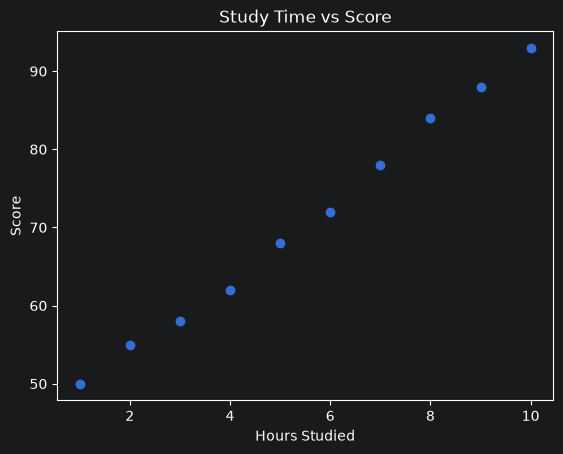

In [68]:
plt.scatter(students["hours_studied"], students["score"])
plt.xlabel("Hours Studied")
plt.ylabel("Score")
plt.title("Study Time vs Score")
plt.show()


## Step 3: Train a model

Two things worth noticing here. `hours_studied` and `attendance` rise almost in lockstep — when features carry nearly the
same information (**multicollinearity**), the overall fit is still fine but the individual coefficients become unstable and should
not be read as separate effects. And with 10 rows the test set holds 2 rows, so this MAE is a single draw from a very noisy
distribution.


In [69]:
X = students[["hours_studied", "attendance"]]
y = students["score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Predictions:", y_pred)
print("MAE:", mean_absolute_error(y_test, y_pred))


Predictions: [87.89995622 53.48051664]
MAE: 0.809763572679504


## Step 4: Make one custom prediction

A prediction must be supplied in the **same shape, with the same column names and order**, as the data the model was fitted
on — which is why the new student is a DataFrame rather than a bare list. Stay inside the range of the training data as well: this
model saw 1–10 study hours, and asking it about 40 hours would be **extrapolation**, where the straight line keeps rising with no
evidence that reality does.


In [70]:
new_student = pd.DataFrame({
    "hours_studied": [7],
    "attendance": [88]
})

predicted_score = model.predict(new_student)
print("Predicted score:", predicted_score)


Predicted score: [77.58121716]


## Step 5: Validate the model

The MAE from Step 3 rests on just 2 test rows — change `random_state` and it will move noticeably. Before trusting the
model, check that its performance holds up across **different** splits. `cross_val_score` runs 5-fold cross-validation: every
student ends up in a test fold exactly once, and we get five MAE values instead of one.

scikit-learn always *maximises* scores, so error metrics are reported negated (`"neg_mean_absolute_error"`); the minus sign
in the code flips them back. Read the result in two parts: the **mean** is the expected error on new students, the **standard
deviation** shows how much that error depends on which students the model happened to see. A small mean with a small spread is
what you want; a large spread means the dataset is too small to judge the model with confidence.

As a sanity check, compare against a **baseline** that ignores the features and always predicts the average score. A model
that cannot clearly beat this baseline has not learned anything useful.


In [71]:
from sklearn.dummy import DummyRegressor

cv_mae = -cross_val_score(LinearRegression(), X, y, cv=5, scoring="neg_mean_absolute_error")
print("MAE per fold:", cv_mae.round(2))
print(f"Mean MAE: {cv_mae.mean():.2f} (+/- {cv_mae.std():.2f})")

baseline_mae = -cross_val_score(DummyRegressor(strategy="mean"), X, y, cv=5, scoring="neg_mean_absolute_error")
print(f"Baseline MAE: {baseline_mae.mean():.2f}")


MAE per fold: [3.21 1.57 1.1  1.2  0.8 ]
Mean MAE: 1.58 (+/- 0.86)
Baseline MAE: 15.15
